# Phần 2 (Giai đoạn 1). Thiết kế Cơ sở Dữ liệu và Tính Phổ điểm THPT (`schema.sql`, `config.py`, `1_import_data_to_sql.py`, `Procedures.sql`, `run_data.sql`)

Notebook này trình bày trọn vẹn **Giai đoạn 1** trong lộ trình hệ thống: từ khởi tạo kiến trúc Cơ sở dữ liệu quan hệ `ady` trên SQL Server, thiết lập kết nối trung tâm bằng Python, kiểm toán và nạp hơn **4,29 triệu bản ghi** điểm thi tốt nghiệp THPT (2023–2026), đến tự động hóa tính toán bảng thống kê phổ điểm `ThongKePhoDiem_Cache`.

Mỗi tệp mã nguồn được **tách nhỏ thành từng khối lệnh ngắn (4–12 dòng)** kèm giải thích tác dụng và kết quả chạy thực tế trên kho dữ liệu `ady` để thấy rõ cách các bước nhỏ ghép lại thành quy trình hoàn chỉnh.

**Luồng làm việc của Giai đoạn 1:**

    Giai đoạn 1. Thiết kế CSDL & Tính Phổ điểm THPT
    ├── 2.1 Thiết kế Sơ đồ CSDL quan hệ (ERD) & Từ điển dữ liệu (schema.sql)
    ├── 2.2 Thiết lập kết nối trung tâm Python – SQL Server (config.py)
    ├── 2.3 Kiểm toán 4 tệp CSV điểm thi gốc & Nạp kho theo lô (1_import_data_to_sql.py)
    │   ├── Khảo sát cấu trúc cột 4 năm (2023–2026)
    │   ├── Khai báo RENAME_MAP, COLS_TO_KEEP, SCORE_COLS
    │   └── Thực nghiệm từng bước làm sạch SBD, điểm thi & kiểm chứng Staging_BangDiem
    ├── 2.4 Thủ tục tính điểm khối & Đóng gói phổ điểm (Procedures.sql, run_data.sql)
    └── 2.5 Trực quan hóa biến động phổ điểm 2023–2026 & Bàn giao sang Giai đoạn 2

---
### 2.1. Thiết kế Sơ đồ CSDL quan hệ (ERD) và Từ điển Dữ liệu (`schema.sql`)

Trong tệp `schema.sql`, hệ thống khởi tạo cơ sở dữ liệu **`ady`** gồm **12 bảng chính thức** (cùng 2 bảng vùng đệm `Staging_BangDiem` và `Staging_DiemChuan` sinh ra khi nạp dữ liệu). Trước khi tạo bảng mới, kịch bản dùng `DROP TABLE IF EXISTS` xóa các **bảng con** (chứa `FOREIGN KEY`) trước rồi mới xóa **bảng cha** (chứa `PRIMARY KEY`) để có thể chạy lại nhiều lần không báo lỗi.

**Sơ đồ liên kết khóa chính (`PK`) – khóa ngoại (`FK`) trong kho dữ liệu `ady`:**

```text
[DanhMucMonHoc] (PK: ma_mon) ──────┬──< [BangDiem] (FK: ma_mon)
                                   └──< [ChiTietToHop] (PK/FK: ma_to_hop, ma_mon) >── [DanhMucToHop] (PK: ma_to_hop)

[Staging_BangDiem] (4,29 triệu thí sinh) ──(sp_XuLyDuLieuTheoNam)──> [KetQuaXetTuyen] (8,43 triệu dòng tổ hợp)
                                                                              │
                                                              (sp_UpdateThongKePhoDiem_Cache)
                                                                              ▼
                                                             [ThongKePhoDiem_Cache] (PK: Nam, Ma_To_Hop)

[DanhMucTruong] (PK: ma_truong) ───┬──< [ChiTieuTruong] (FK: ma_truong)
                                   ├──< [DiemChuanTruong] (FK: ma_truong) <──(sp_DongBo)── [Staging_DiemChuan]
                                   └──< [MappingNganh] (FK: ma_truong, ma_nganh_chuan) >── [DanhMucNganhChuan]
```

**Bảng Từ điển Dữ liệu (Data Dictionary) của 12 bảng khởi tạo trong `schema.sql`:**

| STT | Tên bảng | Các cột chính & Kiểu dữ liệu SQL | Khóa & Ràng buộc | Vai trò trong hệ thống |
|---|---|---|---|---|
| 1 | `DanhMucMonHoc` | `ma_mon VARCHAR(20)`, `ten_mon NVARCHAR(100)` | `PK: ma_mon` | Lưu danh mục 12 môn thi THPT (gồm cả `TIN`, `CN_CN`, `CN_NN`, `GD_PL` từ năm 2025) |
| 2 | `BangDiem` | `id INT`, `nam_hoc INT`, `SOBAODANH NVARCHAR(20)`, `ma_mon VARCHAR(20)`, `diem_so DECIMAL(4,2)`, `ma_ngoai_ngu VARCHAR(20)` | `PK: id`, `FK: ma_mon` | Cấu trúc bảng dọc chuẩn hóa lưu điểm từng môn của thí sinh |
| 3 | `DanhMucTruong` | `ma_truong VARCHAR(20)`, `ten_truong NVARCHAR(255)` | `PK: ma_truong` | Bảng cha quản lý mã trường và tên tiếng Việt của các trường đại học |
| 4 | `ChiTieuTruong` | `id INT`, `nam_hoc INT`, `ma_truong VARCHAR(20)`, `chuong_trinh_dao_tao NVARCHAR(255)`, `ma_xet_tuyen VARCHAR(1000)`, `chi_tieu INT`, `ty_le_chi_tieu_thpt FLOAT` | `PK: id`, `FK: ma_truong` | Lưu tổng chỉ tiêu và tỷ lệ chỉ tiêu dành cho xét điểm thi THPT (2023–2026) |
| 5 | `DiemChuanTruong` | `id INT`, `nam_hoc INT`, `ma_truong VARCHAR(20)`, `chuong_trinh_dao_tao NVARCHAR(255)`, `ma_xet_tuyen VARCHAR(1000)`, `diem_chuan DECIMAL(4,2)` | `PK: id`, `FK: ma_truong` | Lưu lịch sử điểm chuẩn trúng tuyển THPT giai đoạn 2022–2025 |
| 6 | `DanhMucToHop` | `ma_to_hop VARCHAR(10)`, `ten_to_hop NVARCHAR(100)` | `PK: ma_to_hop` | Danh mục các tổ hợp môn xét tuyển (`A00`, `A01`, `D01`, `X06`...) |
| 7 | `ChiTietToHop` | `ma_to_hop VARCHAR(10)`, `ma_mon VARCHAR(20)` | `PK: (ma_to_hop, ma_mon)` | Bảng trung gian định nghĩa 3 môn thành phần của mỗi tổ hợp |
| 8 | `ToHopNgoaiNgu` | `ma_to_hop VARCHAR(5)`, `ma_ngoai_ngu VARCHAR(2)` | Bảng quy ước | Quy định mã ngoại ngữ đi kèm khối thi (ví dụ `N1` Tiếng Anh cho `A01`, `D01`) |
| 9 | `KetQuaXetTuyen` | `id INT`, `nam_hoc INT`, `SOBAODANH NVARCHAR(20)`, `ma_to_hop VARCHAR(10)`, `TongDiem DECIMAL(5,2)` | `PK: id` | Lưu tổng điểm 3 môn thành phần của từng thí sinh theo từng khối Công nghệ |
| 10 | `DanhMucNganhChuan` | `ma_nganh_chuan VARCHAR(50)`, `ten_nganh_chuan NVARCHAR(255)` | `PK: ma_nganh_chuan` | Danh mục 5 phân nhóm ngành Công nghệ – Kỹ thuật chuẩn của đề tài |
| 11 | `MappingNganh` | `id INT`, `ma_truong VARCHAR(20)`, `chuong_trinh_dao_tao_goc NVARCHAR(255)`, `ma_nganh_chuan VARCHAR(50)` | `PK: id`, `FK: ma_truong, ma_nganh_chuan` | Bảng ánh xạ tên chương trình đào tạo đặc thù về 5 phân nhóm chuẩn |
| 12 | `ThongKePhoDiem_Cache` | `Nam INT`, `Ma_To_Hop VARCHAR(10)`, `Diem_Trung_Binh DECIMAL(5,2)`, `So_Luong_Tren_22 INT`, `So_Luong_Tren_25 INT`, `So_Luong_Tren_27 INT`, `Tong_So_Thi_Sinh INT` | `PK: (Nam, Ma_To_Hop)` | Bảng lưu sẵn thống kê phổ điểm theo từng Năm – Khối để AI truy xuất tức thì |

---
### 2.2. Thiết lập Kết nối Trung tâm Python – SQL Server (`config.py`)

Thay vì viết lặp lại địa chỉ máy chủ ở mọi tệp `.py`, tệp `config.py` gom cấu hình kết nối về một nơi duy nhất qua 2 bước ngắn gọn.

**Đoạn code nhỏ 1 (Bước 1 trong `config.py`) — Khai báo tên máy chủ và tên kho dữ liệu:** Tiền tố `r` (*raw string*) đặt trước chuỗi `r".\SQLEXPRESS"` giúp Python giữ nguyên ký tự gạch chéo ngược `\` mà không hiểu nhầm thành ký tự điều khiển.

In [1]:
import os, sys
if os.path.basename(os.getcwd()) == 'báo cáo dự án':
    os.chdir('..')
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

SERVER_NAME = r".\SQLEXPRESS"
DATABASE_NAME = "ady"
print("Máy chủ SQL Server:", SERVER_NAME)
print("Tên cơ sở dữ liệu :", DATABASE_NAME)

Máy chủ SQL Server: .\SQLEXPRESS
Tên cơ sở dữ liệu : ady

**Đoạn code nhỏ 2 (Bước 2 trong `config.py`) — Ghép chuỗi kết nối `DB_CONNECTION_STRING` và mở đường ống `engine`:** Kết nối sử dụng `ODBC Driver 17 for SQL Server` với chế độ `trusted_connection=yes` (đăng nhập trực tiếp bằng quyền Windows hiện tại, không cần mật khẩu rời).

In [2]:
import pandas as pd
import numpy as np
from sqlalchemy import create_engine
from config import DB_CONNECTION_STRING

engine = create_engine(DB_CONNECTION_STRING, fast_executemany=True)
print("Chuỗi kết nối chuẩn:", DB_CONNECTION_STRING)

Chuỗi kết nối chuẩn: mssql+pyodbc://@.\SQLEXPRESS/ady?driver=ODBC+Driver+17+for+SQL+Server&trusted_connection=yes

**Kiểm chứng trực tiếp trên SQL Server:** Truy vấn danh sách các bảng và số lượng bản ghi hiện có trong kho `ady`, đồng thời kiểm tra bảng `DanhMucMonHoc` (12 môn thi THPT).

In [3]:
q_tables = "SELECT TABLE_NAME FROM INFORMATION_SCHEMA.TABLES WHERE TABLE_TYPE = 'BASE TABLE' ORDER BY TABLE_NAME"
df_tables = pd.read_sql(q_tables, engine)
print(f"Tổng số bảng hiện có trong CSDL '{DATABASE_NAME}': {len(df_tables)} bảng")
print(list(df_tables['TABLE_NAME']))

Tổng số bảng hiện có trong CSDL 'ady': 14 bảng
['BangDiem', 'ChiTietToHop', 'ChiTieuTruong', 'DanhMucMonHoc', 'DanhMucNganhChuan', 'DanhMucToHop', 'DanhMucTruong', 'DiemChuanTruong', 'KetQuaXetTuyen', 'MappingNganh', 'Staging_BangDiem', 'Staging_DiemChuan', 'ThongKePhoDiem_Cache', 'ToHopNgoaiNgu']

In [4]:
df_mon = pd.read_sql("SELECT * FROM DanhMucMonHoc", engine)
print(df_mon.to_string(index=False))

   ma_mon                ten_mon
    CN_CN  Công nghệ công nghiệp
    CN_NN  Công nghệ nông nghiệp
      DIA                    Địa
    GD_PL GD Kinh tế & Pháp luật
      HOA                    Hóa
       LY                     Lý
NGOAI_NGU              Ngoại ngữ
     SINH                   Sinh
       SU                     Sử
      TIN                Tin học
     TOAN                   Toán
      VAN                    Văn

**Kết luận mục 2.2:** Kết nối từ Python sang SQL Server hoạt động ổn định; toàn bộ 12 bảng gốc của `schema.sql` (cùng 2 bảng nháp `Staging_BangDiem`, `Staging_DiemChuan`) và danh mục 12 môn thi THPT (bao gồm các môn mới từ năm 2025 là `TIN`, `CN_CN`, `CN_NN`, `GD_PL`) đã sẵn sàng.

---
### 2.3. Kiểm toán 4 Tệp CSV Điểm thi Gốc và Nạp Kho (`1_import_data_to_sql.py`)

#### 2.3.1. Khảo sát cấu trúc thô của 4 tệp CSV điểm thi (2023–2026)
Trước khi chạy lệnh nạp dữ liệu, ta đọc thử dòng đầu và đếm tổng số thí sinh trên cả 4 tệp CSV trong `data_raw/` để kiểm tra xem tên cột giữa các năm có đồng nhất hay không.

In [5]:
tong_thi_sinh_4_nam = 0
for nam in [2023, 2024, 2025, 2026]:
    duong_dan = f"data_raw/diem_thpt_{nam}.csv"
    df_mau = pd.read_csv(duong_dan, nrows=2, dtype=str)
    with open(duong_dan, encoding="utf-8") as f:
        so_dong = sum(1 for _ in f) - 1
    tong_thi_sinh_4_nam += so_dong
    print(f"Năm {nam}: {so_dong:>1,d} thí sinh | {df_mau.shape[1]:2d} cột -> {list(df_mau.columns)}")
print(f"\n=> TỔNG CỘNG BẢN GHI THÍ SINH 4 NĂM: {tong_thi_sinh_4_nam:,d} dòng")

Năm 2023: 1,022,060 thí sinh | 11 cột -> ['sbd', 'toan', 'ngu_van', 'ngoai_ngu', 'vat_li', 'hoa_hoc', 'sinh_hoc', 'lich_su', 'dia_li', 'gdcd', 'ma_ngoai_ngu']
Năm 2024: 1,061,605 thí sinh | 11 cột -> ['sbd', 'toan', 'ngu_van', 'ngoai_ngu', 'vat_li', 'hoa_hoc', 'sinh_hoc', 'lich_su', 'dia_li', 'gdcd', 'ma_ngoai_ngu']
Năm 2025: 1,000,000 thí sinh | 15 cột -> ['STT', 'SOBAODANH', 'Toán', 'Văn', 'Lí', 'Hóa', 'Sinh', 'Tin học', 'Công nghệ công nghiệp', 'Công nghệ nông nghiệp', 'Sử', 'Địa', 'Giáo dục kinh tế và pháp luật', 'Ngoại ngữ', 'Mã môn ngoại ngữ']
Năm 2026: 1,208,863 thí sinh | 15 cột -> ['sbd', 'dm1', 'dm2', 'dm3', 'dm4', 'dm5', 'dm6', 'dm7', 'dm8', 'dm9', 'dm10', 'dm11', 'dm12', 'dm13', 'ngoai_ngu']

=> TỔNG CỘNG BẢN GHI THÍ SINH 4 NĂM: 4,292,528 dòng

**Xem chi tiết 2 dòng đầu của tệp `diem_thpt_2026.csv` để phát hiện bẫy tên cột Ngoại ngữ:**

In [6]:
mau_2026 = pd.read_csv("data_raw/diem_thpt_2026.csv", nrows=2, dtype=str)
print(mau_2026[['sbd', 'dm1', 'dm2', 'dm3', 'dm7', 'dm10', 'ngoai_ngu']].to_string(index=False))

     sbd dm1 dm2 dm3 dm7 dm10 ngoai_ngu
01000001 4.5 7.5 NaN NaN  NaN       NaN
01000002 6.5 7.5 NaN NaN  NaN       NaN

**Kết luận kiểm toán dữ liệu điểm thi thô (Lý do cần 8 bước xử lý trong `1_import_data_to_sql.py`):**
1. **Ba kiểu đặt tên cột lệch nhau qua 4 năm:** Năm 2023–2024 dùng chữ thường không dấu (`toan`, `vat_li`...); năm 2025 dùng tiếng Việt có dấu (`Toán`, `Lí`, `Tin học`...) kèm cột thừa `STT`; năm 2026 lại ký hiệu bằng mã `dm1` đến `dm13`.
2. **Bẫy trùng tên cột `'ngoai_ngu'` ở riêng năm 2026:** Ở tệp năm 2026, cột `'ngoai_ngu'` thực chất lưu mã môn ngoại ngữ (`N1`, `N2`...), trong khi điểm số thực nằm ở cột `'dm3'`. Nếu đổi thẳng `'dm3'` thành `'Ngoai_ngu'` trước sẽ gây trùng tên cột.
3. **Nguy cơ mất số `0` đầu ở Số báo danh:** Số báo danh thí sinh Hà Nội bắt đầu bằng `'01...'` (ví dụ `'01000001'`), nên bắt buộc đọc bằng `dtype=str` và cắt đuôi `'.0'` nếu có.

#### 2.3.2. Bóc tách từng đoạn code nhỏ trong `1_import_data_to_sql.py`

**Đoạn code nhỏ 1 (Phần 2 trong `1_import_data_to_sql.py`) — Khai báo từ điển `RENAME_MAP`, danh sách 15 cột chuẩn `COLS_TO_KEEP` và 12 cột điểm `SCORE_COLS`:**

In [7]:
RENAME_MAP = {
    'sbd': 'SOBAODANH', 'toan': 'Toan', 'ngu_van': 'Van', 'vat_li': 'Li',
    'hoa_hoc': 'Hoa', 'sinh_hoc': 'Sinh', 'lich_su': 'Su', 'dia_li': 'Dia',
    'gdcd': 'GD_KT_PL', 'ngoai_ngu': 'Ngoai_ngu', 'ma_ngoai_ngu': 'Ma_ngoai_ngu',
    'STT': 'STT', 'SOBAODANH': 'SOBAODANH', 'Toán': 'Toan', 'Văn': 'Van',
    'Lí': 'Li', 'Hóa': 'Hoa', 'Sinh': 'Sinh', 'Tin học': 'Tin_hoc',
    'Công nghệ công nghiệp': 'Cong_nghe_CN', 'Công nghệ nông nghiệp': 'Cong_nghe_NN',
    'Sử': 'Su', 'Địa': 'Dia', 'Giáo dục kinh tế và pháp luật': 'GD_KT_PL',
    'Ngoại ngữ': 'Ngoai_ngu', 'Mã môn ngoại ngữ': 'Ma_ngoai_ngu',
    'dm1': 'Toan', 'dm2': 'Van', 'dm3': 'Ngoai_ngu', 'dm4': 'Su', 'dm5': 'Dia',
    'dm6': 'GD_KT_PL', 'dm7': 'Li', 'dm8': 'Hoa', 'dm9': 'Sinh',
    'dm10': 'Tin_hoc', 'dm11': 'Mon_Khac_11', 'dm12': 'Cong_nghe_CN', 'dm13': 'Cong_nghe_NN'
}
COLS_TO_KEEP = [
    'nam_hoc', 'SOBAODANH', 'Toan', 'Van', 'Li', 'Hoa', 'Sinh',
    'Tin_hoc', 'Cong_nghe_CN', 'Cong_nghe_NN', 'Su', 'Dia', 'GD_KT_PL', 'Ngoai_ngu', 'Ma_ngoai_ngu'
]
SCORE_COLS = [
    'Toan', 'Van', 'Li', 'Hoa', 'Sinh', 'Tin_hoc',
    'Cong_nghe_CN', 'Cong_nghe_NN', 'Su', 'Dia', 'GD_KT_PL', 'Ngoai_ngu'
]
print(f"Đã khai báo {len(RENAME_MAP)} quy tắc ánh xạ tên cột -> giữ lại {len(COLS_TO_KEEP)} cột chuẩn.")

Đã khai báo 39 quy tắc ánh xạ tên cột -> giữ lại 15 cột chuẩn.

**Đoạn code nhỏ 2 (Bước 1, 2, 3 trong vòng lặp `1_import_data_to_sql.py`) — Đọc tệp dạng chữ (`dtype=str`), gỡ bẫy cột `'ngoai_ngu'` năm 2026 và ánh xạ tên cột chuẩn:** Ta chạy thử trực tiếp trên 500 thí sinh đầu tiên của năm `2026` để kiểm chứng.

In [8]:
nam = 2026
df_demo = pd.read_csv(f"data_raw/diem_thpt_{nam}.csv", dtype=str, nrows=500)

if nam == 2026 and 'ngoai_ngu' in df_demo.columns:
    df_demo = df_demo.rename(columns={'ngoai_ngu': 'Ma_ngoai_ngu'})

df_demo = df_demo.rename(columns=RENAME_MAP)
print("Các cột sau Bước 3:", list(df_demo.columns))

Các cột sau Bước 3: ['SOBAODANH', 'Toan', 'Van', 'Ngoai_ngu', 'Su', 'Dia', 'GD_KT_PL', 'Li', 'Hoa', 'Sinh', 'Tin_hoc', 'Mon_Khac_11', 'Cong_nghe_CN', 'Cong_nghe_NN', 'Ma_ngoai_ngu']

**Đoạn code nhỏ 3 (Bước 4 & Bước 5 trong `1_import_data_to_sql.py`) — Làm sạch `SOBAODANH` qua 4 dòng lệnh đơn giản và điền cột `None` cho các môn khuyết:**

In [9]:
df_demo = df_demo.dropna(subset=['SOBAODANH'])
df_demo = df_demo.drop_duplicates(subset=['SOBAODANH'])
df_demo['SOBAODANH'] = df_demo['SOBAODANH'].str.replace('.0', '', regex=False)
df_demo['SOBAODANH'] = df_demo['SOBAODANH'].str.strip()

df_demo['nam_hoc'] = nam
for ten_cot in COLS_TO_KEEP:
    if ten_cot not in df_demo.columns:
        df_demo[ten_cot] = None
print("Mẫu Số báo danh sau làm sạch:", list(df_demo['SOBAODANH'].head(5)))

Mẫu Số báo danh sau làm sạch: ['01000001', '01000002', '01000003', '01000004', '01000005']

**Đoạn code nhỏ 4 (Bước 6 & Bước 7 trong `1_import_data_to_sql.py`) — Ép kiểu số `pd.to_numeric`, lọc điểm sai miền (`< 0` hoặc `> 10`) và gọt về đúng 15 cột chuẩn `COLS_TO_KEEP`:**

In [10]:
for mon_hoc in SCORE_COLS:
    df_demo[mon_hoc] = pd.to_numeric(df_demo[mon_hoc], errors='coerce')
    df_demo.loc[df_demo[mon_hoc] < 0, mon_hoc] = None
    df_demo.loc[df_demo[mon_hoc] > 10, mon_hoc] = None

df_demo = df_demo[COLS_TO_KEEP]
print(f"Kích thước khung chuẩn sau Bước 7: {df_demo.shape}")
print(df_demo[['nam_hoc', 'SOBAODANH', 'Toan', 'Van', 'Li', 'Tin_hoc', 'Ngoai_ngu', 'Ma_ngoai_ngu']].head(3).to_string(index=False))

Kích thước khung chuẩn sau Bước 7: (500, 15)
 nam_hoc SOBAODANH  Toan  Van   Li  Tin_hoc  Ngoai_ngu Ma_ngoai_ngu
    2026  01000001   4.5  7.5  NaN      NaN        NaN          NaN
    2026  01000002   6.5  7.5  NaN      NaN        NaN          NaN
    2026  01000003   6.5  7.5 6.85      NaN        NaN          NaN

**Cơ chế Bước 8 (Đẩy lô lớn vào `Staging_BangDiem`):** Trong `1_import_data_to_sql.py`, năm đầu tiên (`nam == 2023`) dùng `che_do_nap = 'replace'` để làm mới bảng nháp, còn các năm `2024, 2025, 2026` dùng `che_do_nap = 'append'` kết hợp `chunksize=100000` (mỗi lần đẩy 100.000 thí sinh để không tràn RAM).

Dưới đây là truy vấn kiểm chứng trực tiếp bảng `Staging_BangDiem` trong SQL Server sau khi hoàn tất nạp cả 4 năm:

In [11]:
q_staging = """
SELECT nam_hoc,
       COUNT(SOBAODANH) AS so_thi_sinh,
       ROUND(AVG(Toan), 2) AS tb_toan,
       ROUND(AVG(Li), 2) AS tb_li,
       ROUND(AVG(Hoa), 2) AS tb_hoa,
       ROUND(AVG(Ngoai_ngu), 2) AS tb_ngoai_ngu,
       ROUND(AVG(Tin_hoc), 2) AS tb_tin_hoc,
       COUNT(Tin_hoc) AS sl_thi_tin
FROM Staging_BangDiem
GROUP BY nam_hoc
ORDER BY nam_hoc
"""
df_st_check = pd.read_sql(q_staging, engine)
print(df_st_check.to_string(index=False))

 nam_hoc  so_thi_sinh  tb_toan  tb_li  tb_hoa  tb_ngoai_ngu  tb_tin_hoc  sl_thi_tin
    2023      1022060     6.25   6.57    6.74          5.46         NaN           0
    2024      1061605     6.45   6.67    6.68          5.52         NaN           0
    2025      1000000     4.84   7.02    6.12          5.44        6.82        6057
    2026      1208863     5.65   5.56    6.28          5.09        6.07       18264

**Kết luận mục 2.3:** Toàn bộ **4.292.528 thí sinh** của 4 năm đã nằm đầy đủ trong `Staging_BangDiem`. Bảng thống kê xác nhận rõ năm 2023–2024 chưa thi môn Tin học (`sl_thi_tin = 0`), từ năm 2025 bắt đầu xuất hiện môn Tin học và quy mô thí sinh dự thi môn Tin học tăng vọt lên năm 2026.

---
### 2.4. Thủ tục Tính điểm Khối và Đóng gói `ThongKePhoDiem_Cache` (`Procedures.sql`, `run_data.sql`)

Nếu mỗi lần huấn luyện AI lại phải quét trực tiếp hơn 4,29 triệu dòng trong `Staging_BangDiem`, hệ thống sẽ mất nhiều phút chờ đợi. Do đó, dự án thiết kế hai tệp SQL làm việc nối tiếp nhau:

1. **Tệp `Procedures.sql`:** Cài đặt sẵn 2 công thức tự động (Stored Procedures):
   - `sp_DongBo_DiemChuanTruong`: Tự động đăng ký mã trường mới vào `DanhMucTruong` (tránh lỗi `FOREIGN KEY`), xóa dữ liệu trùng năm cũ và chép điểm chuẩn từ `Staging_DiemChuan` sang `DiemChuanTruong`.
   - `sp_UpdateThongKePhoDiem_Cache`: Gom nhóm (`GROUP BY nam_hoc, ma_to_hop`) trên bảng `KetQuaXetTuyen`, cộng thêm **0,5 điểm ưu tiên trung bình** (`TongDiem + 0.5`), rồi tính sẵn `Diem_Trung_Binh` cùng số lượng thí sinh đạt từ **22 điểm**, **25 điểm** và **27 điểm** trở lên (`SUM(CASE WHEN ...)`).
2. **Tệp `run_data.sql`:** Gọi thực thi xử lý điểm 10 khối xét tuyển Công nghệ cho từng năm (`2023` $\rightarrow$ `2026`) lưu vào `KetQuaXetTuyen`, sau đó gọi `EXEC sp_UpdateThongKePhoDiem_Cache` để đóng gói kết quả gọn nhẹ vào `ThongKePhoDiem_Cache`.

**Đoạn code nhỏ 1 — Kiểm tra quy mô bảng `KetQuaXetTuyen` trong SQL Server:**

In [12]:
q_kq = """
SELECT nam_hoc, COUNT(*) AS so_ban_ghi_to_hop, COUNT(DISTINCT ma_to_hop) AS so_khoi_thi
FROM KetQuaXetTuyen
GROUP BY nam_hoc
ORDER BY nam_hoc
"""
print(pd.read_sql(q_kq, engine).to_string(index=False))

 nam_hoc  so_ban_ghi_to_hop  so_khoi_thi
    2023            3106948            8
    2024            3248568            8
    2025             974682            9
    2026            1107164            9

**Đoạn code nhỏ 2 — Truy vấn kết quả bảng `ThongKePhoDiem_Cache` cho các tổ hợp xét tuyển khối Công nghệ:**

In [13]:
q_cache = """
SELECT Nam, Ma_To_Hop, Diem_Trung_Binh,
       So_Luong_Tren_22, So_Luong_Tren_25, So_Luong_Tren_27, Tong_So_Thi_Sinh,
       CAST(So_Luong_Tren_25 * 100.0 / NULLIF(Tong_So_Thi_Sinh, 0) AS DECIMAL(5,2)) AS Ty_Le_25_Pct,
       CAST(So_Luong_Tren_27 * 100.0 / NULLIF(Tong_So_Thi_Sinh, 0) AS DECIMAL(5,2)) AS Ty_Le_27_Pct
FROM ThongKePhoDiem_Cache
WHERE Ma_To_Hop IN ('A00', 'A01', 'C01', 'D01', 'X06', 'X26')
ORDER BY Ma_To_Hop, Nam
"""
df_pho_cache = pd.read_sql(q_cache, engine)
print(df_pho_cache.to_string(index=False))

 Nam Ma_To_Hop  Diem_Trung_Binh  So_Luong_Tren_22  So_Luong_Tren_25  So_Luong_Tren_27  Tong_So_Thi_Sinh  Ty_Le_25_Pct  Ty_Le_27_Pct
2023       A00            21.28            147791             31295              4090            325864          9.60          1.26
2024       A00            21.41            164345             48538              8024            343736         14.12          2.33
2025       A00            20.03             50125             22622              8965            143615         15.75          6.24
2026       A00            19.91             63967             22072              5520            175232         12.60          3.15
2023       A01            20.78            120066             32644              4771            314380         10.38          1.52
2024       A01            20.97            135949             37657              4892            328809         11.45          1.49
2025       A01            19.47             35812              9714         

---
### 2.5. Trực quan hóa Biến động Phổ điểm THPT (2023–2026) và Tổng kết Giai đoạn 1

Từ dữ liệu thực tế vừa truy vấn trên `Staging_BangDiem` và `ThongKePhoDiem_Cache`, ta vẽ biểu đồ đối chiếu biến động mặt bằng điểm môn thi và tỷ lệ thí sinh đạt ngưỡng điểm giỏi ($\ge 25,0$ điểm) của các khối chủ lực xét tuyển ngành Công nghệ.

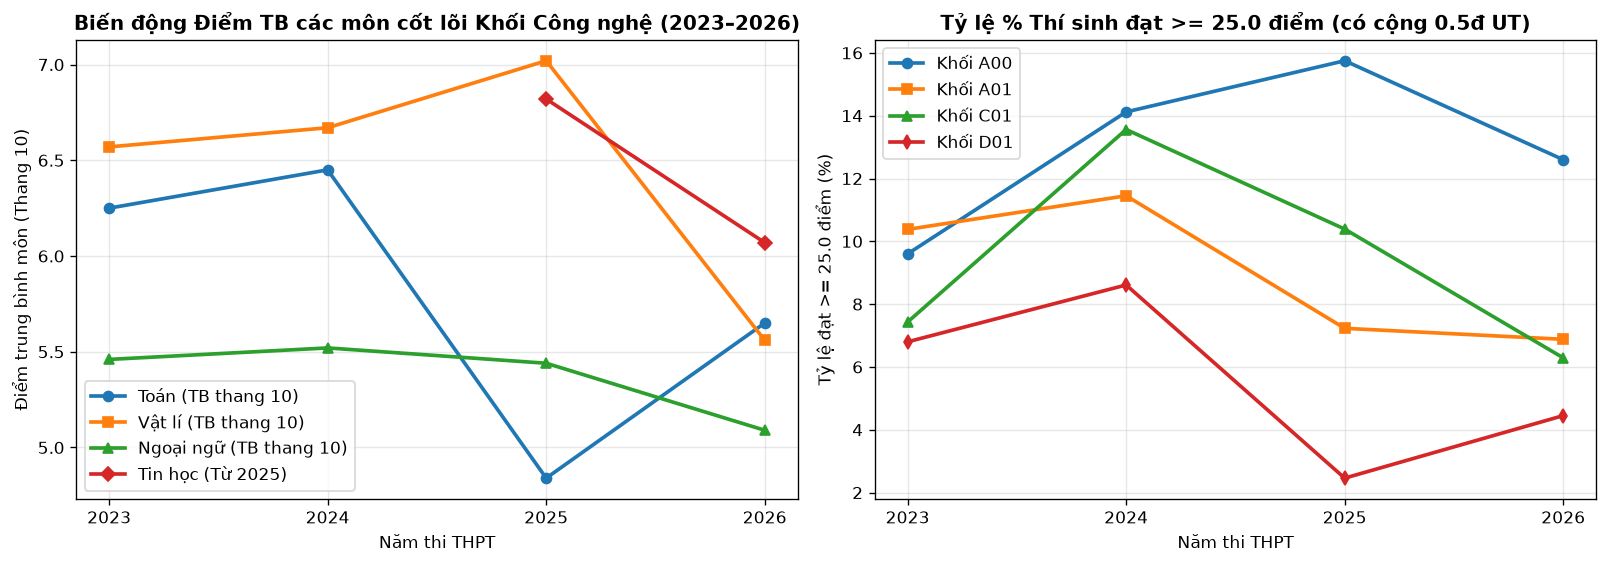

In [14]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8), dpi=120)
nam_str = df_st_check['nam_hoc'].astype(str).tolist()

axes[0].plot(nam_str, df_st_check['tb_toan'], marker='o', linewidth=2.2, label='Toán (TB thang 10)')
axes[0].plot(nam_str, df_st_check['tb_li'], marker='s', linewidth=2.2, label='Vật lí (TB thang 10)')
axes[0].plot(nam_str, df_st_check['tb_ngoai_ngu'], marker='^', linewidth=2.2, label='Ngoại ngữ (TB thang 10)')
df_tin = df_st_check[df_st_check['sl_thi_tin'] > 0]
axes[0].plot(df_tin['nam_hoc'].astype(str), df_tin['tb_tin_hoc'], marker='D', linewidth=2.2, label='Tin học (Từ 2025)')
axes[0].set_title('Biến động Điểm TB các môn cốt lõi Khối Công nghệ (2023–2026)', fontweight='bold')
axes[0].set_xlabel('Năm thi THPT'); axes[0].set_ylabel('Điểm trung bình môn (Thang 10)')
axes[0].grid(alpha=0.3); axes[0].legend()

for khoi, marker in [('A00', 'o'), ('A01', 's'), ('C01', '^'), ('D01', 'd')]:
    sub = df_pho_cache[df_pho_cache['Ma_To_Hop'] == khoi].sort_values('Nam')
    axes[1].plot(sub['Nam'].astype(str), sub['Ty_Le_25_Pct'], marker=marker, linewidth=2.2, label=f'Khối {khoi}')
axes[1].set_title('Tỷ lệ % Thí sinh đạt >= 25.0 điểm (có cộng 0.5đ UT)', fontweight='bold')
axes[1].set_xlabel('Năm thi THPT'); axes[1].set_ylabel('Tỷ lệ đạt >= 25.0 điểm (%)')
axes[1].grid(alpha=0.3); axes[1].legend()
plt.tight_layout()
plt.show()

**Nhận xét và Ý nghĩa thực tiễn tuyển sinh:**
- Biểu đồ bên trái phản ánh rõ tác động của kỳ thi đổi mới từ năm 2025: điểm trung bình môn Toán giảm mạnh vào năm 2025 (do cấu trúc đề thi phân hóa mới gồm trắc nghiệm đúng/sai và trả lời ngắn) trước khi phục hồi nhẹ vào năm 2026, trong khi môn Vật lí và môn Tin học mới duy trì mặt bằng điểm khá tốt.
- Biểu đồ bên phải cho thấy sự phân hóa mạnh về nguồn cung thí sinh điểm giỏi ($\ge 25,0$ điểm) giữa các tổ hợp: khối truyền thống `A00` giữ tỷ lệ điểm giỏi cao vượt trội so với các khối có môn Tiếng Anh (`A01`, `D01`) trong hai năm 2025–2026.
- Hiện tượng điểm trung bình toàn quốc giảm nhưng tỷ lệ điểm giỏi ở khối `A00` vẫn dồi dào giải thích vì sao điểm chuẩn các ngành Công nghệ mũi nhọn (như AI, Khoa học máy tính, Vi mạch) tại các trường Top 1 không hề giảm sâu theo điểm trung bình chung.
- Đây là căn cứ trực tiếp để nhóm đưa đồng thời cả `Diem_Trung_Binh` lẫn tỷ lệ thí sinh đạt $\ge 25$ và $\ge 27$ điểm từ bảng `ThongKePhoDiem_Cache` vào mô hình dự báo ở Giai đoạn 4 và Giai đoạn 5.

#### Bảng tổng kết Giai đoạn 1 bàn giao sang Giai đoạn 2 (File 3)

| Hạng mục hoàn thành | Tệp mã nguồn thực thi | Kết quả lưu trữ trong CSDL `ady` |
|---|---|---|
| Khởi tạo kiến trúc CSDL & Kết nối | `schema.sql`, `config.py` | 12 bảng chuẩn hóa có ràng buộc khóa `PK / FK` tại `.\SQLEXPRESS` (`ady`) |
| Chuẩn hóa & Nạp điểm thi THPT | `1_import_data_to_sql.py` | **4.292.528** thí sinh (2023–2026) đồng bộ về 15 cột chuẩn trong `Staging_BangDiem` |
| Tính điểm khối & Đóng gói Cache | `Procedures.sql`, `run_data.sql` | **8.437.362** bản ghi tổ hợp (`KetQuaXetTuyen`) nén gọn thành bảng `ThongKePhoDiem_Cache` |